
# Lab 9: Quantun Computing - Rabi Oscillations

Nombre estudiante: Bernardo Alejandro Mendoza Montes

c.c: 1001363373

## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule

![NH3](../Sesiones/QC/figures/NH3.png)
![NH3](NH3.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.

 [see](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

In [14]:
!pip install qiskit
!pip install qiskit_aer
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 107.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 112.8 MB/s  0:00:00


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import Aer

In [5]:
# Constantes

frec = 24.79e9 # Frecuencia de Rabi en Hz
omega = 2*np.pi*frec # Frec. angular en RAD

frec_rabi = frec*2/(np.sqrt(5)) # Frecuencia de Rabi en Hz
omega_rabi = 2*np.pi*(24.79e9*(2/np.sqrt(5)))
delta = omega_rabi/2


print(f"Frecuencia de Rabi (Hz): {frec_rabi:.4e} Hz ({frec_rabi/1e9:.2f} GHz)")
print(f"Frecuencia de Rabi angular: {omega_rabi:.4e} rad/s")

Frecuencia de Rabi (Hz): 2.2173e+10 Hz (22.17 GHz)
Frecuencia de Rabi angular: 1.3932e+11 rad/s


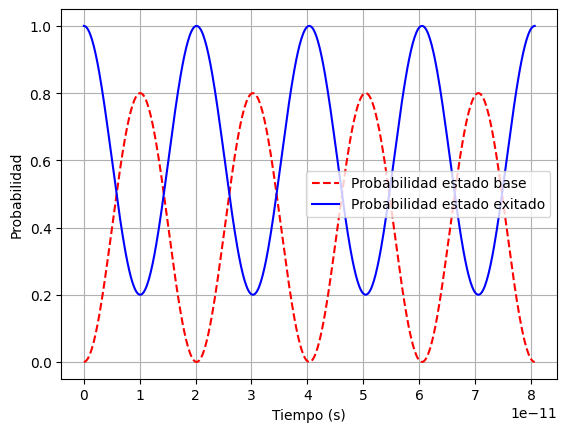

In [12]:
# Intervalo de tiempo (4 oscilaciones)

T = np.pi / omega
t = np.linspace(0, 4 * T, 500)

# Probabilidades P(1) y P(2) con estado inicial en P(2)

P2 = np.cos(omega*t)**2 + ((delta/omega)**2)*np.sin(omega*t)**2
P1 = 1 - P2

plt.plot(t, P1, label='Probabilidad estado base', linestyle="--", color="red")
plt.plot(t, P2, label='Probabilidad estado exitado', color="blue")
plt.xlabel('Tiempo (s)')
plt.ylabel('Probabilidad')
plt.grid()
plt.legend()
plt.show()

## Exercise: Bell state

1. Creates a quantum circuit for two qubits, consisting of the quantum gates needed to create a `Bell state`  (two entangled qubits). The quantum circuit then terminates with quantum measurements, extracting one bit from each qubit.

2. Add a third qubit by changing to QuantumCircuit(3), and add a second CX gate with qc.cx(1,2). The measurements should then change to 000 and 111, which means all three of these qubits have been entangled.

3. See your results shift by adding qc.x(1) to the end of the circuit.